# 02 · Feature engineering: "how differently did this service behave after the fault?"

Every row of our table = **one candidate service in one case**. Its features compare the 12 minutes *after* the injection with the 12 minutes *before*, using only that case's own data:

| Source | Features (per service) | Idea |
|---|---|---|
| Metrics | for each metric type (cpu, mem, diskio, socket, workload, error, latency-50, latency-90): **max robust z-score** after the fault, mean z-score, relative change of the mean | "how far outside its normal range did it go?" |
| Logs | change in log volume, change in error-like lines, share of log *templates* never seen before the fault | "did it start complaining, or go quiet?" |
| Traces | change in span count, p50/p95 latency change, worst single operation's p95 change, error-rate change | "did its requests get slower or fail?" |
| Ranks | every feature's **rank among the services of the same case** | makes systems with 12 and 68 services comparable |

### Robust z-score (the key statistic)
For a metric, take the normal window, compute its **median** and **IQR** (spread of the middle 50%). After the fault, `z = (value − median) / IQR`. Median/IQR instead of mean/std because one spike in the normal window would otherwise inflate the "normal" spread. This is the same idea as **BARO** (FSE 2024), a strong published method on this benchmark.

### Leakage rules
- No feature uses the label, other cases, or anything after the case's own time window.
- **Service names are not features.** Otherwise the model would just learn "the benchmark only breaks these 5 services", a shortcut that is useless in real life.
- Features are computed per case with fixed rules (nothing is *fitted*), so they cannot leak test information into training.

The features are built by `scripts/build_features.py` (parallel, ~1–3 s per case; Train Ticket is the slowest).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message=".*(mismatched devices|pandas version 4).*")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
RESULTS = ROOT / "reports" / "results"; RESULTS.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

from rcalens.data import load_features
df, has_traces = load_features()
print("feature table:", df.shape, "| trace features included:", has_traces)
print("cases:", df["case"].nunique(), "| rows per case (candidate services):", df.groupby("system")["service"].nunique().to_dict())
df.head(3)

feature table: (8548, 78) | trace features included: True
cases: 270 | rows per case (candidate services): {'ob': 12, 'ss': 15, 'tt': 68}


,case,service,m_cpu_maxz,m_cpu_meanz,m_cpu_rel,m_mem_maxz,m_mem_meanz,m_mem_rel,m_diskio_maxz,m_diskio_meanz,m_diskio_rel,m_socket_maxz,m_socket_meanz,m_socket_rel,m_workload_maxz,m_workload_meanz,m_workload_rel,m_latency50_maxz,m_latency50_meanz,m_latency50_rel,...,m_error_maxz_rank,m_error_meanz_rank,m_error_rel_rank,m_all_maxz_rank,l_rate_ratio_rank,l_err_ratio_rank,l_err_share_post_rank,l_new_tmpl_share_rank,t_count_ratio_rank,t_p50_ratio_rank,t_p95_ratio_rank,t_worst_op_p95_ratio_rank,t_err_rate_diff_rank,n_services,system,fault,pair,repetition,root_cause_service,is_rc
0,re2ob_checkoutservice_cpu_1,adservice,1.169344,-0.196896,-0.011400,0.921157,0.590024,0.001105,0.917844,0.175223,0.030654,0.000000,0.000000,-0.004141,1.044282,-0.042973,0.000652,0.760772,0.244423,0.001999,...,NaN,NaN,NaN,0.166667,0.4,0.5,0.5,0.4,NaN,NaN,NaN,NaN,NaN,12,ob,cpu,ob|checkoutservice|cpu,1,checkoutservice,0
1,re2ob_checkoutservice_cpu_1,cartservice,1.267930,0.028328,0.012603,1.791759,0.341288,0.000447,NaN,NaN,NaN,0.000000,0.000000,0.000000,1.009143,-0.038252,0.000806,1.080346,-0.272827,-0.012220,...,NaN,NaN,NaN,0.583333,0.5,0.5,0.5,0.8,NaN,NaN,NaN,NaN,NaN,12,ob,cpu,ob|checkoutservice|cpu,1,checkoutservice,0
2,re2ob_checkoutservice_cpu_1,checkoutservice,5.468693,5.376147,3.753005,2.830230,2.712681,0.325822,NaN,NaN,NaN,5.408168,5.388648,0.197134,1.152153,0.192879,0.040370,1.004441,0.244462,0.055189,...,NaN,NaN,NaN,0.916667,0.8,0.5,0.5,0.9,1.0,1.0,0.714286,1.0,0.571429,12,ob,cpu,ob|checkoutservice|cpu,1,checkoutservice,1


In [2]:
src = {"metrics": [c for c in df.columns if c.startswith("m_") and not c.endswith("_rank")],
       "logs": [c for c in df.columns if c.startswith("l_") and not c.endswith("_rank")],
       "traces": [c for c in df.columns if c.startswith("t_") and not c.endswith("_rank")]}
cover = {s: {k: float(df.loc[df.system == s, v].notna().any(axis=1).mean()) if v else 0.0 for k, v in src.items()} for s in ["ob", "ss", "tt"]}
print({k: len(v) for k, v in src.items()}, "raw features (+ the same number of rank features)")
pd.DataFrame(cover).T.round(2).rename_axis("share of services with this source")

{'metrics': 26, 'logs': 4, 'traces': 5} raw features (+ the same number of rank features)


,metrics,logs,traces
share of services with this source,,,
ob,1.0,0.84,0.58
ss,1.0,0.72,0.00
tt,1.0,0.65,0.38


Not every service has every source: some services write no logs, Sock Shop has no traces, databases have no latency metrics. **XGBoost handles missing values natively**, so we keep them as missing instead of inventing values.

## Do the features separate root causes from innocent services?

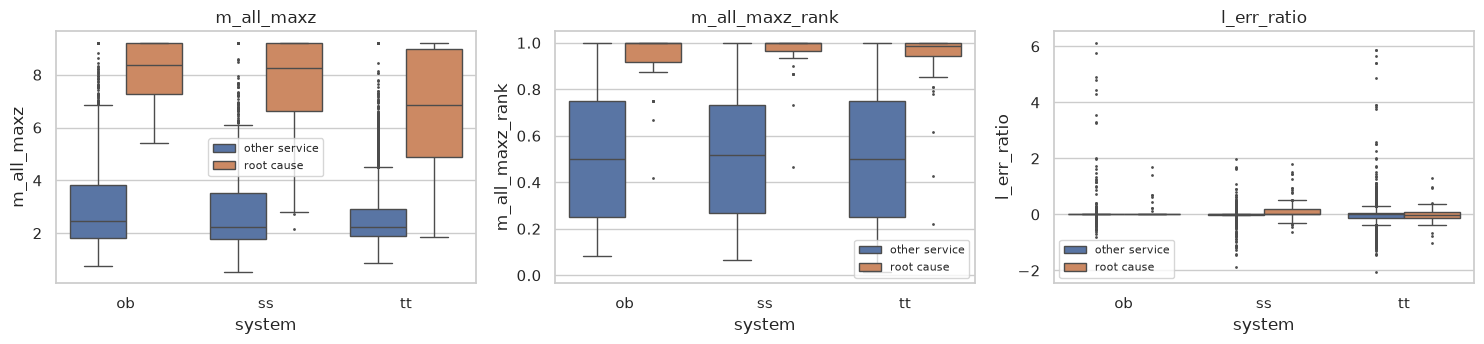

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["m_all_maxz", "m_all_maxz_rank", "l_err_ratio"]):
    if col in df:
        sns.boxplot(data=df, x="system", y=col, hue=df["is_rc"].map({0: "other service", 1: "root cause"}), ax=ax, fliersize=1)
        ax.set_title(col); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The root cause usually has the most extreme metric change in its case (rank close to 1.0), but the boxes overlap: innocent services can look just as extreme (e.g. a caller suffering from the root cause's delay).

## Which metric reacts to which fault? (root-cause services only)

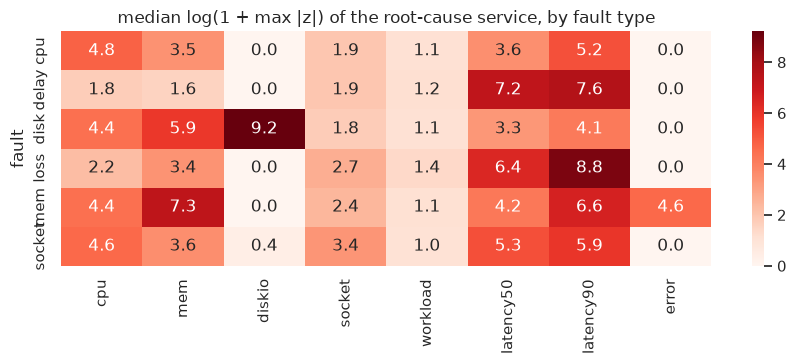

In [4]:
rc = df[df["is_rc"] == 1]
types = [c for c in df.columns if c.startswith("m_") and c.endswith("_maxz") and c != "m_all_maxz"]
heat = rc.groupby("fault")[types].median().rename(columns=lambda c: c[2:-5])
plt.figure(figsize=(9, 3.8)); sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds")
plt.title("median log(1 + max |z|) of the root-cause service, by fault type"); plt.tight_layout()
plt.savefig(FIG / "fault_signatures.png", dpi=120); plt.show()

**This is the "signature" of each fault:** CPU faults show up in `cpu`, memory faults in `mem`, disk faults in `diskio`, while **delay / loss** faults mostly show in latency and are the hard ones (the latency also rises in the services that call the culprit). These signatures are also what lets us classify the **fault type** (notebook 04).

### Recap
- One row per (case, candidate service), ~95 features from three sources, plus within-case ranks.
- Robust (median/IQR) statistics of each case's own normal window; no labels, no service names.

➡️ Next: **03_baselines**: how far do simple rules get?